# Movie Ratings Analysis

Analyzing critic and audience ratings of popular movies released between 2007 and 2011.

## Importing Libraries & Settings

In [32]:
# import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [33]:
# display settings
%matplotlib inline
plt.rcParams["figure.figsize"] = (10, 5)
sns.set_theme()

## Loading Data

In [34]:
# load movie_ratings_data.csv and preview the DataFrame
df = pd.read_csv("./data/movie_ratings_data.csv")
df.head()

,Film,Genre,Rotten Tomatoes Ratings %,Audience Ratings %,Budget (Mn $),Release Year
0,(500) Days of Summer,Comedy,87,81,8,2009
1,"10,000 B.C.",Adventure,9,44,105,2008
2,12 Rounds,Action,30,52,20,2009
3,127 Hours,Adventure,93,84,18,2010
4,17 Again,Comedy,55,70,20,2009


## Data Profiling

### Shape & Schema

In [35]:
# check shape
df.shape

(559, 6)

In [36]:
# check info and dtypes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 559 entries, 0 to 558
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Film                       559 non-null    str  
 1   Genre                      559 non-null    str  
 2   Rotten Tomatoes Ratings %  559 non-null    int64
 3   Audience Ratings %         559 non-null    int64
 4   Budget (Mn $)              559 non-null    int64
 5   Release Year               559 non-null    int64
dtypes: int64(4), str(2)
memory usage: 38.1 KB


### Fixing Data Types

Convert `Film` and `Genre` from `object` to `category`, and `Release Year` from `int64` to `category` -- it has only 5 fixed levels (2007-2011).

In [37]:
# cast Film, Genre, Release Year to category dtype
categorical_cols = ["Film", "Genre", "Release Year"]
df[categorical_cols] = df[categorical_cols].astype("category")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 559 entries, 0 to 558
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   Film                       559 non-null    category
 1   Genre                      559 non-null    category
 2   Rotten Tomatoes Ratings %  559 non-null    int64   
 3   Audience Ratings %         559 non-null    int64   
 4   Budget (Mn $)              559 non-null    int64   
 5   Release Year               559 non-null    category
dtypes: category(3), int64(3)
memory usage: 28.4 KB


> **Why `category`?**
> - `Film` and `Genre`: string columns with low cardinality -- `category` avoids repeated
>   string storage and makes grouping faster.
> - `Release Year`: only 5 distinct values (2007-2011). Treating it as `category` makes it
>   natural to use as a grouping or facet dimension and prevents accidental numeric operations
>   (e.g., computing a mean year is meaningless).

### Numerical Summary

In [38]:
# describe numerical columns (transposed)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Rotten Tomatoes Ratings %,559.0,47.309481,26.413091,0.0,25.0,46.0,70.0,97.0
Audience Ratings %,559.0,58.744186,16.826887,0.0,47.0,58.0,72.0,96.0
Budget (Mn $),559.0,50.236136,48.731817,0.0,20.0,35.0,65.0,300.0


> **Observations:**
> - **Critics are harsher and more polarized than audiences.** RT mean is ~47% vs audience
>   mean of ~59%. The wider critic std (26 vs 17) shows critics take more extreme positions.
> - **Both metrics have a minimum of 0** -- complete rejection by critics or audiences is
>   present in the dataset.
> - **Budget is right-skewed.** The mean ($50M) is well above the median ($35M), pulled up
>   by a handful of $200M+ blockbusters. The 25th percentile sits at just $20M.

### Rating & Budget Distributions

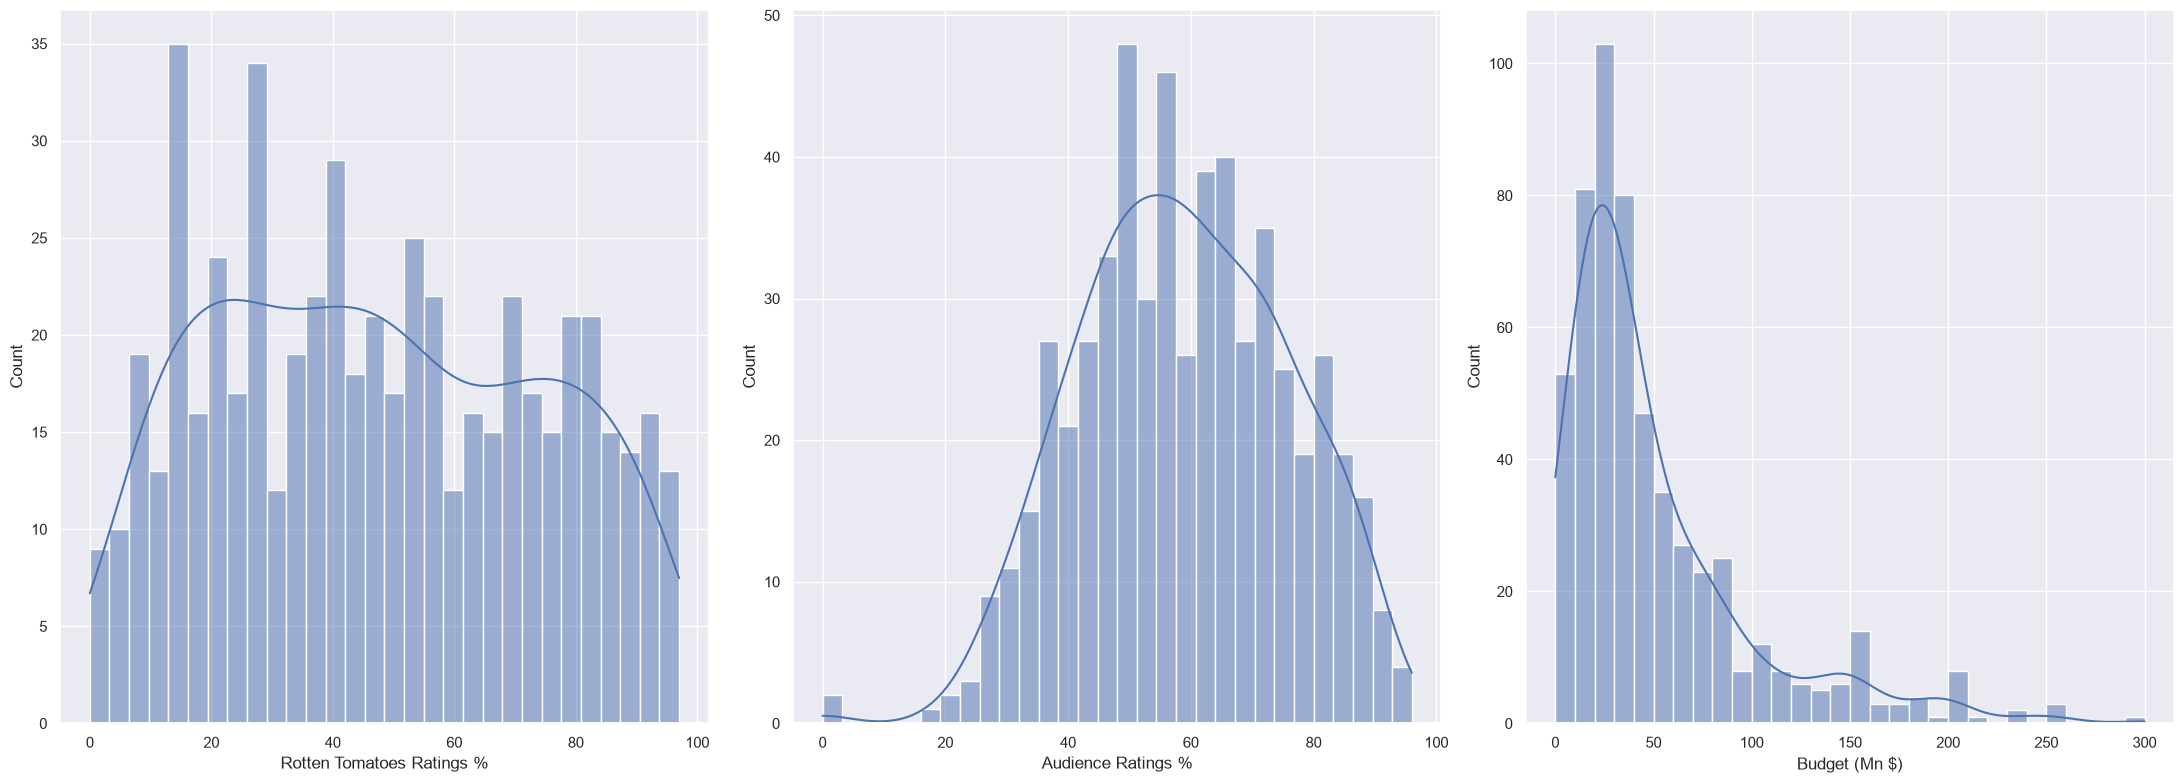

In [39]:
# plot distributions of RT ratings, audience ratings, and budget in 1 row of subplots
fig, axes = plt.subplots(1, 3, figsize=(22, 8))

sns.histplot(df["Rotten Tomatoes Ratings %"], bins=30, kde=True, ax=axes[0])
sns.histplot(df["Audience Ratings %"], bins=30, kde=True, ax=axes[1])
sns.histplot(df["Budget (Mn $)"], bins=30, kde=True, ax=axes[2])

plt.tight_layout()
plt.show()

### Movies by Release Year

In [40]:
# list unique release years
list(df["Release Year"].unique().sort_values())

[2007, 2008, 2009, 2010, 2011]

In [41]:
# count of movies per release year
df.groupby("Release Year")["Film"].count()

Release Year
2007     79
2008    122
2009    116
2010    119
2011    123
Name: Film, dtype: int64

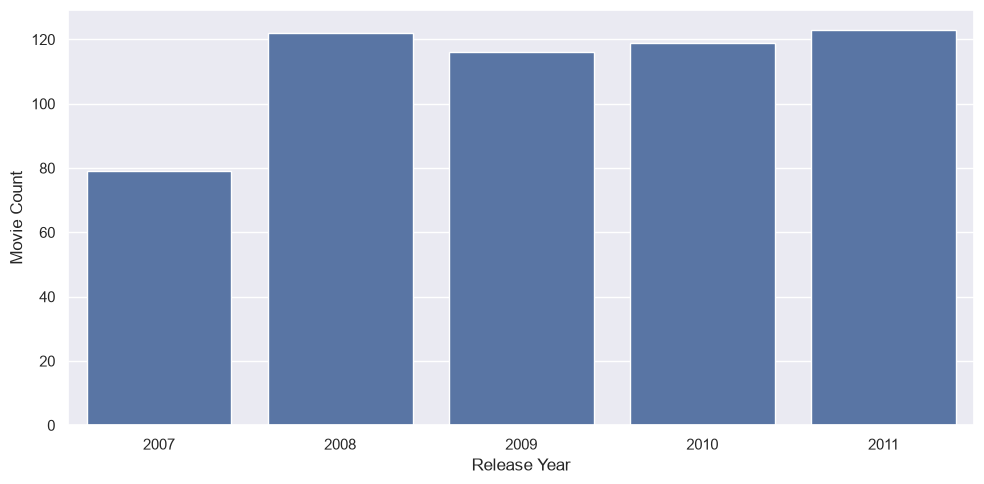

In [42]:
# bar chart -- movie count by release year
movies_per_year = (
    df.groupby("Release Year")["Film"].count().reset_index(name="Movie Count")
)

sns.barplot(data=movies_per_year, x="Release Year", y="Movie Count")
plt.tight_layout()
plt.show()

> **Observation:** The dataset has a fairly even spread across all five years -- between 79
> and 123 films per year. 2007 is the lightest year (79 films); 2008-2011 cluster tightly
> between 116-123. The 2007 dip likely reflects how the source catalog was assembled rather
> than actual release volume.

## Filtering the DataFrame

### Top-10 Movies

In [43]:
# top-10 movies by budget
df.nlargest(10, "Budget (Mn $)")[["Film", "Budget (Mn $)"]]

,Film,Budget (Mn $)
304,Pirates of the Caribbean: At World's End,300
360,Spider-Man 3,258
167,Harry Potter and the Half-Blood Prince,250
303,Pirates of the Caribbean: On Stranger Tides,250
33,Avatar,237
314,Quantum of Solace,230
501,Transformers: Revenge of the Fallen,210
5,2012,200
19,Alice in Wonderland,200
152,Green Lantern,200


In [44]:
# top-10 movies by Rotten Tomatoes ratings
df.nlargest(10, "Rotten Tomatoes Ratings %")[["Film", "Rotten Tomatoes Ratings %"]]

,Film,Rotten Tomatoes Ratings %
387,The Artist,97
431,The Hurt Locker,97
455,The Muppets,97
506,True Grit,96
249,Moneyball,95
275,No Country for Old Men,95
26,An Education,94
196,Iron Man,94
207,Juno,94
362,Star Trek,94


In [45]:
# top-10 movies by audience ratings
df.nlargest(10, "Audience Ratings %")[["Film", "Audience Ratings %"]]

,Film,Audience Ratings %
406,The Dark Knight,96
9,50/50,93
190,Inception,93
530,Warrior,93
33,Avatar,92
196,Iron Man,91
362,Star Trek,91
387,The Artist,91
394,The Bourne Ultimatum,91
428,The Help,91


> **Observations:**
> - **Budget does not predict critical or audience success.** The highest-budget films
>   (Pirates of the Caribbean, Spider-Man 3) appear in neither top-10 rating list.
> - **Critics and audiences sometimes converge.** *Iron Man*, *Star Trek*, and *The Artist*
>   appear in both rating top-10s -- crowd-pleasers that critics also embraced.
> - **The Dark Knight tops the audience list (96%) but not the critic list.** Its RT rating
>   (94%) narrowly misses the critic top-10, illustrating how small gaps can split the lists.

### Movie Details Filter Function

A reusable helper to look up all attributes for a given film title.

In [46]:
# define movie_details(film_name: str) -> pd.Series
def movie_details(film_name: str) -> pd.Series:
    return df.loc[df["Film"] == film_name].iloc[0]

In [47]:
# test: movie_details("Inception")
movie_details("Inception")

Film                         Inception
Genre                           Action
Rotten Tomatoes Ratings %           86
Audience Ratings %                  93
Budget (Mn $)                      160
Release Year                      2010
Name: 190, dtype: object

## Key Takeaways

- **559 films across 2007-2011** with a balanced year spread (79-123 films per year).
- **Critics score lower and more variably than audiences.** Median RT rating is 46% vs
  audience median of 58%. The wider critic distribution (std 26 vs 17) confirms critics
  take stronger positions in both directions.
- **Budget is a poor proxy for quality.** Top-budget franchise films (Pirates, Spider-Man,
  Transformers) score average or below on both rating scales.
- **The critic-audience gap is consistent across the dataset.** Audience ratings track
  roughly 10-15 points above critic ratings on average -- audiences tend to be more
  forgiving regardless of genre or year.